# Chapter 5: Linear Models and Regularization

*Summary notebook for **scikit-learn Cookbook, Third Edition** — Chapter 5.*

Linear regression is probably the first model most of us meet; this chapter takes it from plain OLS to its regularised and non-linear extensions.

**Recipes covered**
1. Introduction to linear models (OLS)
2. Ridge and Lasso regression
3. ElasticNet
4. Regularization theory (bias–variance trade-off)
5. Polynomial regression and spline interpolation
6. Practical exercises

In [1]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, r2_score
pd.set_option('display.precision', 3)

## 1. Introduction to Linear Models

### Summary
A linear model assumes the target is a weighted sum of the features plus noise. It is the backbone for many predictive techniques, highly **interpretable** (each coefficient = effect of one feature, holding others fixed), and the foundation for regularised regression and logistic regression.

### Theory explained
$$y=\beta_0+\beta_1x_1+\beta_2x_2+\dots+\beta_px_p+\epsilon$$

- $\beta_0$ intercept, $\beta_j$ coefficients, $\epsilon$ error term.
- **OLS** chooses $\boldsymbol\beta$ to minimise $\sum_i(y_i-\hat y_i)^2$ (closed form $\boldsymbol\beta=(\mathbf X^T\mathbf X)^{-1}\mathbf X^T\mathbf y$).
- Classical assumptions: linearity, independent errors, constant variance (homoscedasticity), approximately normal residuals, and **no severe multicollinearity**.

**Why multicollinearity hurts OLS.** If features are nearly copies of each other, $\mathbf X^T\mathbf X$ is almost singular, its inverse explodes, and coefficients become huge, unstable, and of arbitrary sign — small changes in the data swing them wildly. Regularization (sections 2–4) is the cure.

### Metrics
- **MSE** $=\frac1n\sum(y_i-\hat y_i)^2$ — lower is better, in squared target units.
- **$R^2$** — fraction of variance explained (can be negative on test data if the model is worse than predicting the mean).

### Setup — a synthetic, deliberately difficult dataset
1,000 samples, 100 features (only 10 informative), noise, and **50 features that are near-copies of the other 50** (multicollinearity). We follow the book's construction (including its odd scaling of the target by 1000 and an added sine/exponential term).

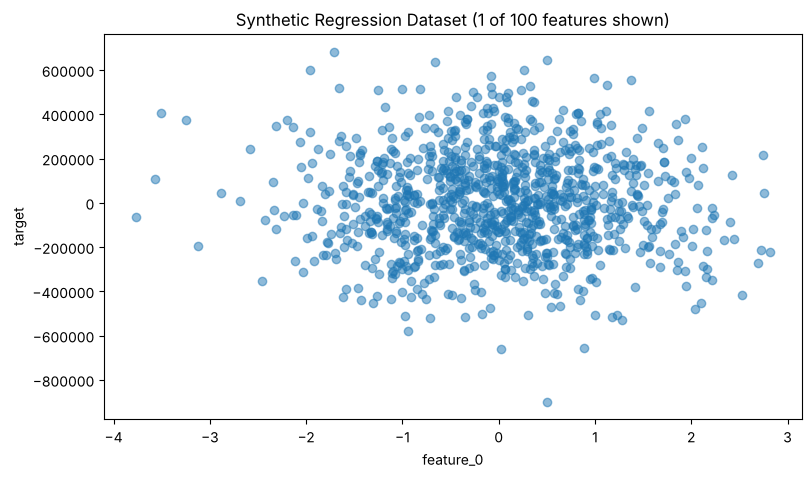

In [2]:
from sklearn.datasets import make_regression

X, y = make_regression(n_samples=1000, n_features=100, n_informative=10, noise=20, random_state=123)

rng = np.random.RandomState(123)
for i in range(50, 100):                     # make half the features correlated copies
    X[:, i] = X[:, i - 50] + rng.normal(0, 0.1, size=1000)

feature_names = [f'feature_{i}' for i in range(100)]
X_plot = X[:, 0].reshape(-1, 1)
y = y * 1000
y = y + np.sin(X_plot.ravel()) * 150 + np.exp(X_plot.ravel() / 10)

df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

plt.figure(figsize=(9, 5))
plt.scatter(X_plot, y, alpha=.5)
plt.xlabel('feature_0'); plt.ylabel('target'); plt.title('Synthetic Regression Dataset (1 of 100 features shown)')
plt.show()

Only one feature is plotted, so the scatter looks noisy — the other 99 features carry most of the signal.

### OLS baseline

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=123)

linear_model = LinearRegression().fit(X_train, y_train)
y_pred_linear = linear_model.predict(X_test)
print(f"Mean Squared Error: {mean_squared_error(y_test, y_pred_linear):,.2f}")
print(f"R-squared: {r2_score(y_test, y_pred_linear):.3f}")

Mean Squared Error: 46,550,591,070.53
R-squared: 0.065


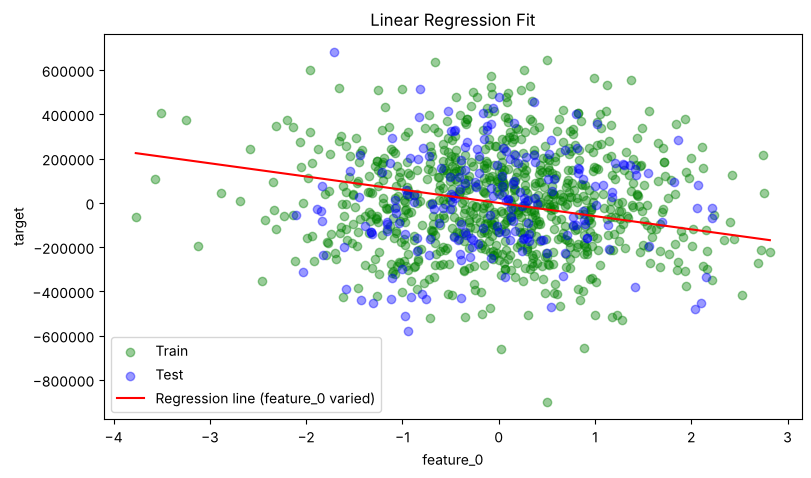

In [4]:
# Regression "line" along feature_0 (all other features held at 0), as in the book
X_line = np.linspace(df['feature_0'].min(), df['feature_0'].max(), 100)
X_line_full = np.zeros((100, 100)); X_line_full[:, 0] = X_line

plt.figure(figsize=(9, 5))
plt.scatter(X_train[:, 0], y_train, color='green', alpha=.4, label='Train')
plt.scatter(X_test[:, 0], y_test, color='blue', alpha=.4, label='Test')
plt.plot(X_line, linear_model.predict(pd.DataFrame(X_line_full, columns=feature_names)), 'r', label='Regression line (feature_0 varied)')
plt.xlabel('feature_0'); plt.ylabel('target'); plt.title('Linear Regression Fit'); plt.legend(); plt.show()

The red line shows only the *marginal* effect of `feature_0` with all other features set to 0 — it will not look like it "passes through" the cloud, because the cloud is driven by many features at once. $R^2$ on the test set is a better summary of quality.

### Other things to explore
Regularised regression (next sections) and logistic regression (Chapter 6).

## 2. Ridge and Lasso Regression

### Summary
Both add a **penalty on coefficient size** to the OLS loss, discouraging complexity and fighting overfitting. The strength is controlled by `alpha` ($\alpha\ge0$; $\alpha=0$ is plain OLS).

### Theory explained
$$\text{Ridge (L2):}\quad \mathcal L=\sum_{i=1}^n(y_i-\hat y_i)^2+\alpha\sum_{j=1}^p\beta_j^2$$
$$\text{Lasso (L1):}\quad \mathcal L=\sum_{i=1}^n(y_i-\hat y_i)^2+\alpha\sum_{j=1}^p|\beta_j|$$

**Geometric intuition.** Minimising the loss subject to a budget on the coefficients: Ridge's constraint region is a **sphere/circle** (smooth), so the optimum rarely lands exactly on an axis → coefficients **shrink toward 0 but stay non-zero**. Lasso's region is a **diamond with corners on the axes**, so the optimum often lands on a corner → some coefficients become **exactly 0** (automatic **feature selection**).

| | Ridge | Lasso |
|:--|:--|:--|
| Penalty | L2 (squares) | L1 (absolute values) |
| Zeroes out coefficients? | No | Yes (sparse model) |
| Correlated features | Spreads weight across them (stable) | Tends to pick one arbitrarily |
| Use when | keep all features, many small effects | suspect many irrelevant features |

> scikit-learn detail: `Ridge` minimises $\lVert y-Xw\rVert^2+\alpha\lVert w\rVert^2$, whereas `Lasso` minimises $\frac1{2n}\lVert y-Xw\rVert^2+\alpha\lVert w\rVert_1$ — so the same numeric `alpha` is **not** comparable between the two. **Standardize features** before penalised models, since penalties depend on coefficient size which depends on feature scale (the book's synthetic features are already roughly unit-scale).

In [5]:
ridge_model = Ridge(alpha=1.0).fit(X_train, y_train)
lasso_model = Lasso(alpha=10.0, max_iter=10000, tol=0.001).fit(X_train, y_train)

preds = {'Ridge Regression': ridge_model.predict(X_test),
         'Lasso Regression': lasso_model.predict(X_test),
         'Linear Regression': y_pred_linear}
metrics_df = pd.DataFrame({
    'Model': list(preds),
    'Mean Squared Error': [mean_squared_error(y_test, p) for p in preds.values()],
    'R-squared': [r2_score(y_test, p) for p in preds.values()],
}).sort_values('Mean Squared Error').reset_index(drop=True)
metrics_df

,Model,Mean Squared Error,R-squared
0,Ridge Regression,4.534e+10,0.089
1,Lasso Regression,4.638e+10,0.068
2,Linear Regression,4.655e+10,0.065


In [6]:
print("Non-zero coefficients -> OLS:", int((linear_model.coef_ != 0).sum()),
      "| Ridge:", int((ridge_model.coef_ != 0).sum()),
      "| Lasso:", int((lasso_model.coef_ != 0).sum()))
print("Largest |coef|        -> OLS: %.0f | Ridge: %.0f | Lasso: %.0f" % (
      np.abs(linear_model.coef_).max(), np.abs(ridge_model.coef_).max(), np.abs(lasso_model.coef_).max()))

Non-zero coefficients -> OLS: 100 | Ridge: 100 | Lasso: 100
Largest |coef|        -> OLS: 168983 | Ridge: 122267 | Lasso: 165217


Two things to read from the table and the counts above: (1) the three models perform **very similarly** on this dataset, so the gap is small; (2) at `alpha=10` Lasso did **not** zero any coefficient here (all 100 stay non-zero, as the counts show): the features are roughly unit-scale while the target is ~1000× larger, so this alpha is mild. Lasso needs a larger `alpha` (or `LassoCV`) before it sparsifies. Don't over-interpret differences from a single split.

### Visual comparison along `feature_0`

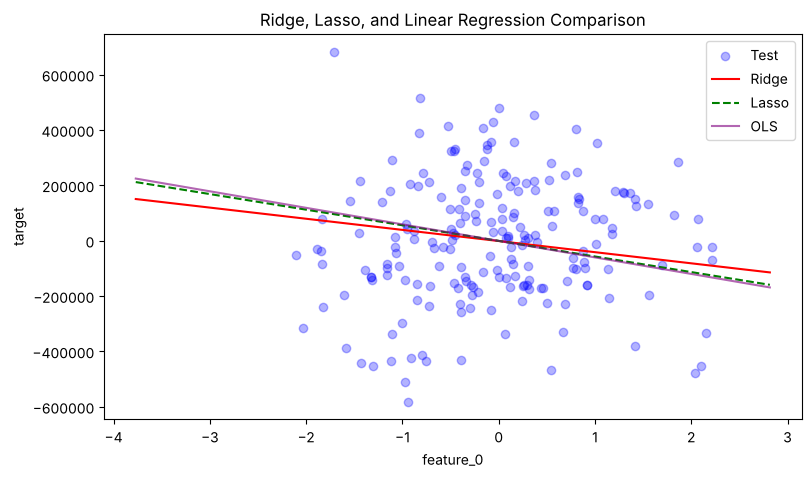

In [7]:
X_line_df = pd.DataFrame(X_line_full, columns=feature_names)
plt.figure(figsize=(9, 5))
plt.scatter(X_test[:, 0], y_test, color='blue', alpha=.3, label='Test')
plt.plot(X_line, ridge_model.predict(X_line_df), 'r', label='Ridge')
plt.plot(X_line, lasso_model.predict(X_line_df), 'g--', label='Lasso')
plt.plot(X_line, linear_model.predict(X_line_df), color='purple', alpha=.6, label='OLS')
plt.xlabel('feature_0'); plt.ylabel('target'); plt.title('Ridge, Lasso, and Linear Regression Comparison'); plt.legend(); plt.show()

## 3. ElasticNet and Regularization

### Summary
ElasticNet **mixes** the L1 and L2 penalties. It keeps Lasso's sparsity but is more stable with groups of correlated features (it tends to keep or drop correlated features together), and it can select more than $n$ features when $p>n$.

### Theory explained
scikit-learn's objective:

$$\mathcal L=\frac1{2n}\sum_i(y_i-\hat y_i)^2+\alpha\Bigl(\rho\,\lVert\boldsymbol\beta\rVert_1+\frac{1-\rho}{2}\lVert\boldsymbol\beta\rVert_2^2\Bigr)$$

- `alpha` ($\alpha$) = overall strength; `l1_ratio` ($\rho\in[0,1]$) = mixing.
- $\rho=1$ → pure Lasso; $\rho\to0$ → Ridge-like; in between → blend. (The book writes the mix with two symbols $\lambda_1,\lambda_2$; `alpha` and `l1_ratio` are the practical parameterisation.)

### Coefficient-path plot
Shows every coefficient as `alpha` grows: more regularization → smaller coefficients; some hit exactly 0. With 100 features the plot is dense, but the **shape** (shrinkage) is the message. Exact zeros appear only at the largest `alpha` and only a few; with this target scale most alphas shrink coefficients without zeroing them.

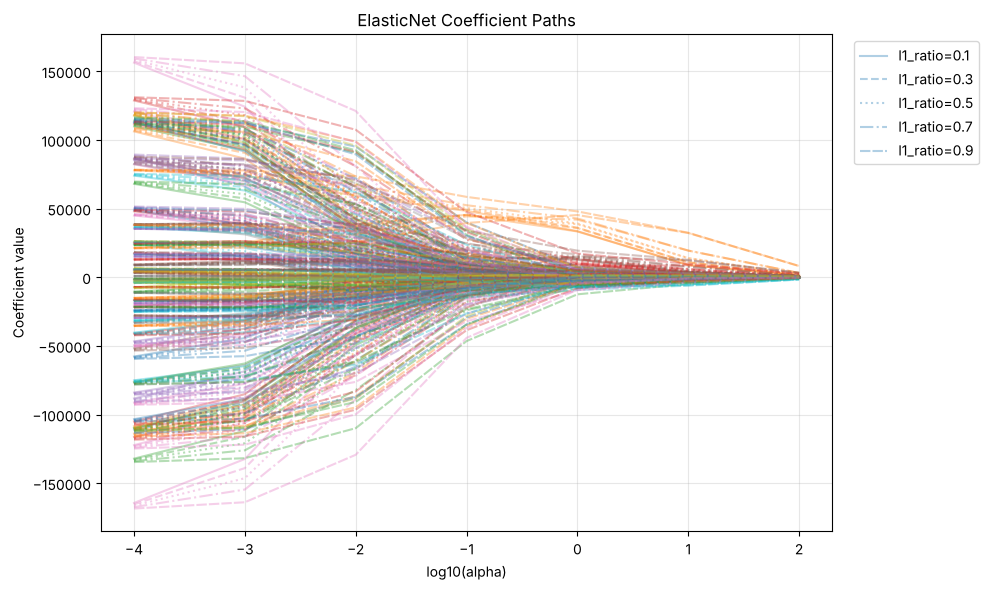

Number of exactly-zero coefficients (out of 100) for alphas [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]
  l1_ratio=0.1: [0 0 0 0 0 0 2]
  l1_ratio=0.3: [0 0 0 0 0 0 2]
  l1_ratio=0.5: [0 0 0 0 0 0 1]
  l1_ratio=0.7: [0 0 0 0 0 0 3]
  l1_ratio=0.9: [0 0 0 0 0 0 0]


In [8]:
alphas = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]
l1_ratios = [0.1, 0.3, 0.5, 0.7, 0.9]
styles = ['solid', 'dashed', 'dotted', 'dashdot', (0, (5, 1))]

plt.figure(figsize=(10, 6))
zero_counts = {}
for ratio, ls in zip(l1_ratios, styles):
    coefs = []
    for a in alphas:
        m = ElasticNet(alpha=a, l1_ratio=ratio, random_state=123, max_iter=10000, tol=1e-4).fit(X_train, y_train)
        coefs.append(m.coef_)
    coefs = np.array(coefs)
    zero_counts[ratio] = (coefs == 0).sum(axis=1)
    for j in range(coefs.shape[1]):
        plt.plot(np.log10(alphas), coefs[:, j], linestyle=ls, alpha=.35,
                 label=f'l1_ratio={ratio}' if j == 0 else None)
plt.xlabel('log10(alpha)'); plt.ylabel('Coefficient value'); plt.title('ElasticNet Coefficient Paths')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left'); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

print("Number of exactly-zero coefficients (out of 100) for alphas", alphas)
for r, z in zero_counts.items():
    print(f"  l1_ratio={r}:", z)

Reading the printout: only 0–3 coefficients (out of 100) become exactly zero, and only at `alpha=100`; elsewhere the penalty shrinks coefficients without eliminating them. Sparsity would need much larger `alpha` on this target scale.

### Fit one balanced ElasticNet and compare all four models

In [9]:
elastic_model = ElasticNet(alpha=1.0, l1_ratio=0.5, random_state=123, max_iter=10000, tol=1e-4).fit(X_train, y_train)
elastic_pred = elastic_model.predict(X_test)

new_row = pd.DataFrame({'Model': ['ElasticNet Regression'],
                        'Mean Squared Error': [mean_squared_error(y_test, elastic_pred)],
                        'R-squared': [r2_score(y_test, elastic_pred)]})
metrics_all = pd.concat([metrics_df, new_row], ignore_index=True).sort_values('Mean Squared Error').reset_index(drop=True)
metrics_all

,Model,Mean Squared Error,R-squared
0,ElasticNet Regression,4.262e+10,0.144
1,Ridge Regression,4.534e+10,0.089
2,Lasso Regression,4.638e+10,0.068
3,Linear Regression,4.655e+10,0.065


Compare the rows: here ElasticNet (alpha=1, l1_ratio=0.5) has the best R² (≈0.144 vs Ridge 0.089, Lasso 0.068, OLS 0.065), consistent with the book — but the margins are small and seed-dependent, so verify on your own split. In practice tune `alpha` and `l1_ratio` with `ElasticNetCV` or `GridSearchCV`.

**Why use it:** automatic feature selection in high-dimensional data with correlated predictors.

## 4. Regularization Theory and Practice

### Summary
Regularization adds a penalty to the loss to prevent **overfitting** and improve **generalisation**: a model could fit training data almost perfectly with a very complex function, but it would be memorising noise. The penalty trades a bit of training fit for simplicity.

### Theory explained — bias–variance trade-off
Expected test error decomposes as

$$\mathbb E[(y-\hat f(x))^2]=\underbrace{\text{Bias}^2}_{\text{too simple}}+\underbrace{\text{Variance}}_{\text{too sensitive to training set}}+\underbrace{\sigma^2}_{\text{irreducible noise}}$$

- Regularization **increases bias slightly** (coefficients are shrunk) but **reduces variance a lot**.
- Too little regularization → overfit (low bias, high variance). Too much → underfit (high bias).
- Goal: choose the strength that minimises error on **unseen** data (validation / cross-validation).

| Type | Penalty | Effect |
|:--|:--|:--|
| L1 (Lasso) | $\alpha\sum|\beta_j|$ | sparsity / feature selection |
| L2 (Ridge) | $\alpha\sum\beta_j^2$ | shrinkage, keeps all features |
| ElasticNet | both | balance; good for correlated features |

Advanced: **group Lasso** (select whole groups of features), **Bayesian regression** (priors on coefficients; Ridge ≡ Gaussian prior, Lasso ≡ Laplace prior).

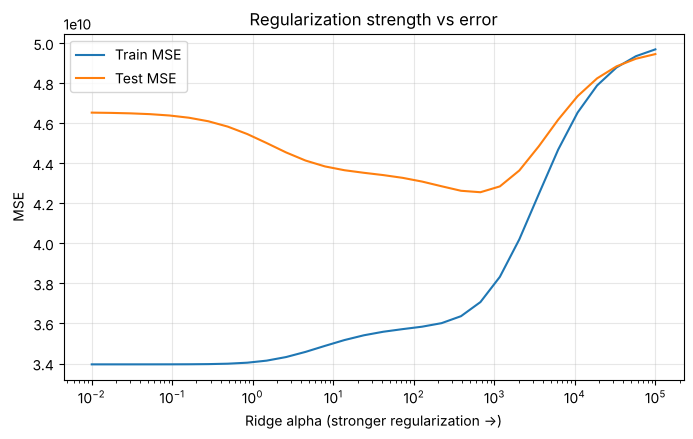

alpha with lowest test MSE: 672.336


In [10]:
# Demonstrate the bias-variance trade-off: test MSE as a function of the Ridge penalty
alphas_r = np.logspace(-2, 5, 30)
tr_err, te_err = [], []
for a in alphas_r:
    m = Ridge(alpha=a).fit(X_train, y_train)
    tr_err.append(mean_squared_error(y_train, m.predict(X_train)))
    te_err.append(mean_squared_error(y_test, m.predict(X_test)))
plt.figure(figsize=(8, 4.5))
plt.semilogx(alphas_r, tr_err, label='Train MSE'); plt.semilogx(alphas_r, te_err, label='Test MSE')
plt.xlabel('Ridge alpha (stronger regularization ->)'); plt.ylabel('MSE'); plt.legend(); plt.grid(alpha=.3)
plt.title('Regularization strength vs error'); plt.show()
print("alpha with lowest test MSE:", round(alphas_r[int(np.argmin(te_err))], 3))

Training error only rises as the penalty strengthens (the model can fit less and less), while test error first falls or stays flat and then rises once the model is over-constrained (underfitting). The optimal `alpha` sits where the test curve is lowest.

## 5. Regression and Regularization: Polynomial Regression and Splines

### Summary
Linear models can capture **non-linear** relationships if we feed them **non-linear features**. Two ways: polynomial features and splines.

### Setup — non-linear data
$y=2x+27\sin(x/8)+\text{noise}$, a line plus a sine wave.

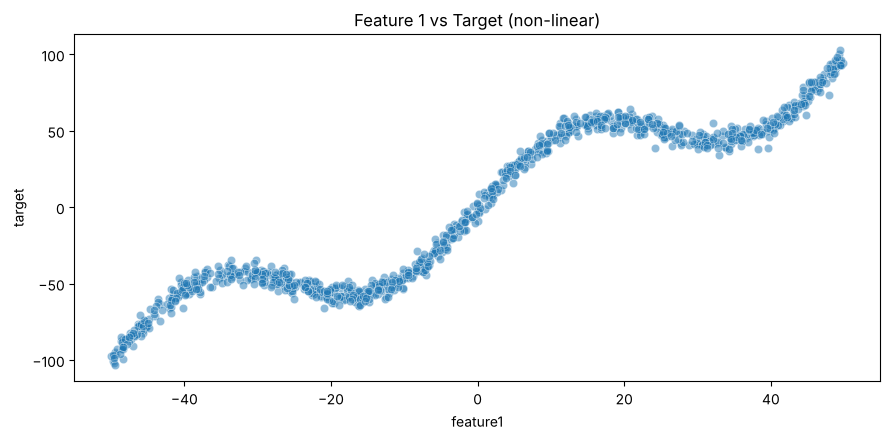

In [11]:
np.random.seed(123)
n = 1000
Xn = np.random.uniform(-50, 50, (n, 1))
yn = 2 * Xn[:, 0] + 27 * np.sin(Xn[:, 0] / 8) + np.random.normal(0, 4, n)
data = pd.DataFrame(Xn, columns=['feature1']); data['target'] = yn

plt.figure(figsize=(9, 4.5)); sns.scatterplot(data=data, x='feature1', y='target', alpha=.5)
plt.title('Feature 1 vs Target (non-linear)'); plt.tight_layout(); plt.show()

### 5.1 Polynomial regression
**Theory.** Expand $x$ to $[x,x^2,\dots,x^d]$ and fit OLS on these columns:
$$y=\beta_0+\beta_1x+\beta_2x^2+\dots+\beta_dx^d+\epsilon$$
The model is still **linear in the coefficients** (so OLS applies) but non-linear in $x$. Higher $d$ → more flexibility → risk of **overfitting** and wild behaviour at the edges (Runge's phenomenon). Don't choose $d$ by in-sample R² — use held-out/CV error.

In [12]:
from sklearn.preprocessing import PolynomialFeatures

Xd, yd = data[['feature1']], data['target']
degrees = [1, 2, 3, 4, 5]
rows = []
for d in degrees:
    Xp = PolynomialFeatures(degree=d).fit_transform(Xd)
    Xtr, Xte, ytr, yte = train_test_split(Xp, yd, test_size=0.2, random_state=123)
    m = LinearRegression().fit(Xtr, ytr)
    p = m.predict(Xte)
    rows.append({'Degree': d, 'MSE': mean_squared_error(yte, p), 'R2': r2_score(yte, p)})
results_df = pd.DataFrame(rows)
print(results_df.to_string(index=False))

 Degree     MSE    R2
      1 317.005 0.891
      2 316.818 0.891
      3 268.477 0.908
      4 268.230 0.908
      5 811.071 0.721


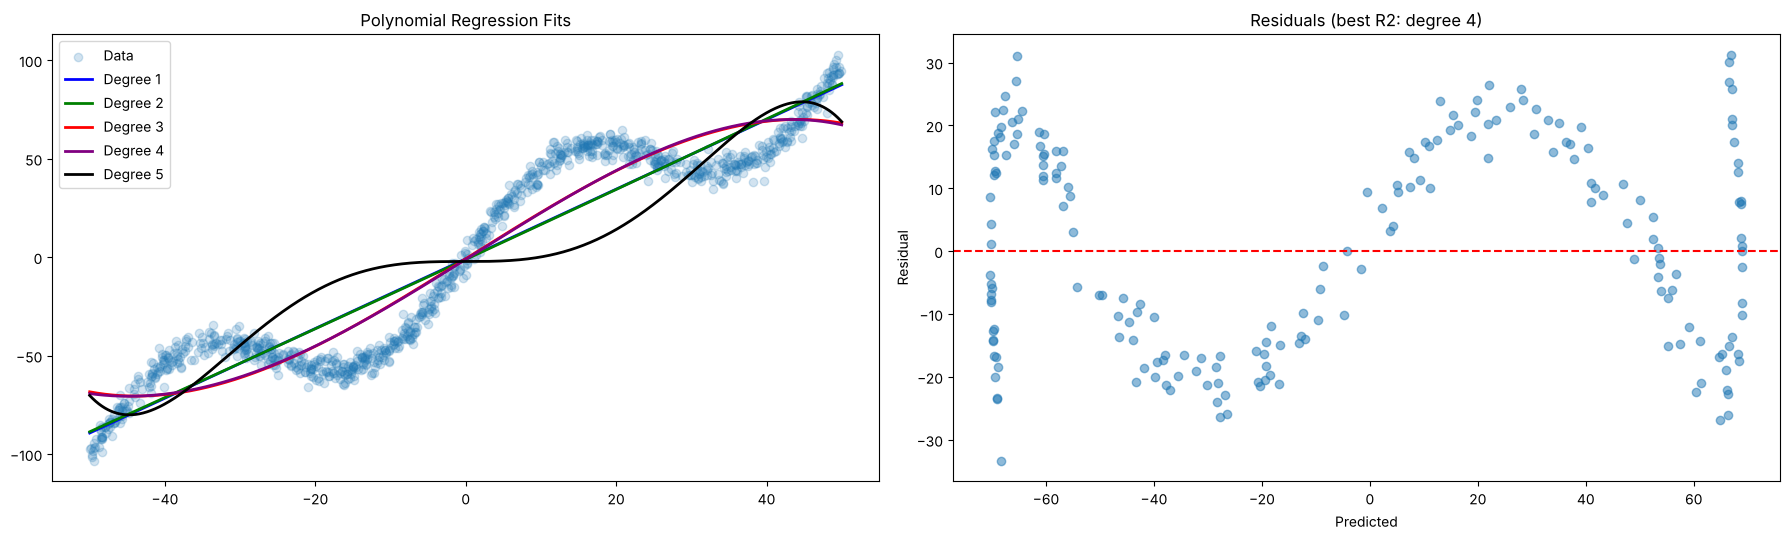

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 5.5))
ax1.scatter(Xd['feature1'], yd, alpha=.2, label='Data')
X_plot2 = np.linspace(-50, 50, 1000).reshape(-1, 1)
for d, c in zip(degrees, ['blue', 'green', 'red', 'purple', 'black']):
    pf = PolynomialFeatures(degree=d)
    m = LinearRegression().fit(pf.fit_transform(Xd), yd)
    ax1.plot(X_plot2, m.predict(pf.transform(X_plot2)), color=c, lw=2, label=f'Degree {d}')
ax1.set_title('Polynomial Regression Fits'); ax1.legend(loc='upper left')

best_degree = int(results_df.loc[results_df['R2'].idxmax(), 'Degree'])
pf = PolynomialFeatures(degree=best_degree); Xb = pf.fit_transform(Xd)
Xtr, Xte, ytr, yte = train_test_split(Xb, yd, test_size=0.2, random_state=123)
mb = LinearRegression().fit(Xtr, ytr); pb = mb.predict(Xte)
ax2.scatter(pb, yte - pb, alpha=.5); ax2.axhline(0, color='r', ls='--')
ax2.set_xlabel('Predicted'); ax2.set_ylabel('Residual'); ax2.set_title(f'Residuals (best R2: degree {best_degree})')
plt.tight_layout(); plt.show()

A straight line (degree 1) cannot follow the sine wave; moderate degrees track it much better (R² ≈0.89 at degrees 1–2 and ≈0.91 at 3–4 in this run), while degree 5 is clearly worse (≈0.72), a sign of overfitting/edge instability. On **real** data a perfect-looking fit may simply mean overfit — which is why the book stresses not relying solely on MSE/R². A **residual plot** should look like random noise around 0; visible structure means the model is missing something.

### 5.2 Spline interpolation (`SplineTransformer`)
**Theory.** Instead of one global polynomial, a **spline** glues together **piecewise polynomials** (here cubic, `degree=3`) joined smoothly at points called **knots**, with continuous value and derivatives at the joins. `SplineTransformer` builds **B-spline basis functions**; a `LinearRegression` on those gives a flexible smooth curve that is *local* (changing one region barely affects others), avoiding polynomial's edge oscillation. More knots → more flexibility (and overfitting risk).

> Terminology: scikit-learn's spline approach is a *regression* spline (least-squares fit through the data), not strict interpolation through every point.

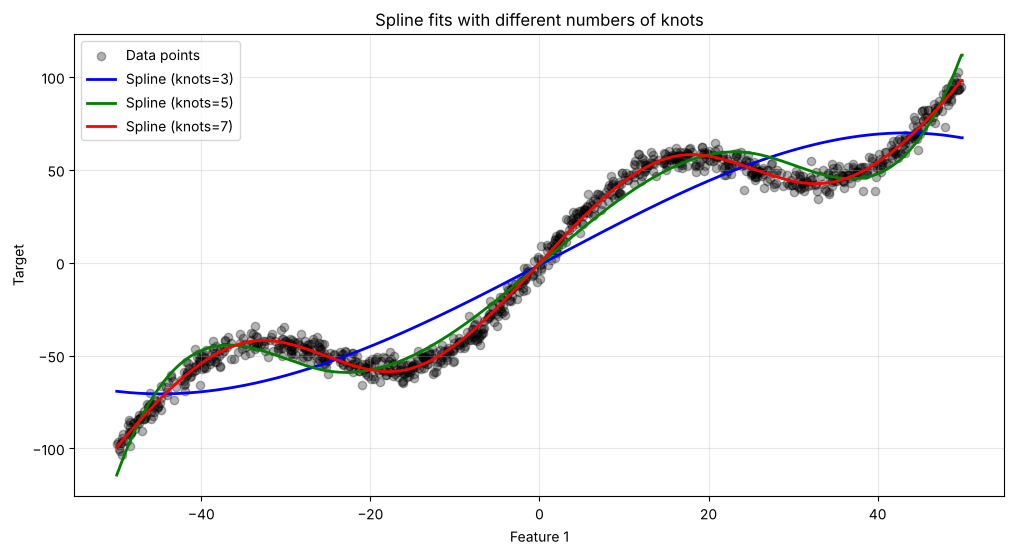

,Number of Knots,MSE,R-squared
0,3,274.267,0.905
1,5,55.348,0.981
2,7,15.502,0.995


In [14]:
from sklearn.preprocessing import SplineTransformer
from sklearn.pipeline import make_pipeline

n_knots_list = [3, 5, 7]
mse_scores, r2_scores = [], []
plt.figure(figsize=(12, 6))
plt.scatter(Xd, yd, color='black', alpha=.3, label='Data points')
for nk, c in zip(n_knots_list, ['blue', 'green', 'red']):
    model = make_pipeline(SplineTransformer(n_knots=nk, degree=3), LinearRegression()).fit(Xd, yd)
    plt.plot(X_plot2, model.predict(X_plot2), color=c, lw=2, label=f'Spline (knots={nk})')
    mse_scores.append(mean_squared_error(yd, model.predict(Xd))); r2_scores.append(r2_score(yd, model.predict(Xd)))
plt.xlabel('Feature 1'); plt.ylabel('Target'); plt.title('Spline fits with different numbers of knots'); plt.legend(); plt.grid(alpha=.3); plt.show()
pd.DataFrame({'Number of Knots': n_knots_list, 'MSE': mse_scores, 'R-squared': r2_scores})

Training MSE falls as knots increase — a better fit to the *training* data (note these are in-sample metrics; to choose the number of knots honestly, use cross-validation). Beyond B-splines, consider natural splines and generalised additive models (GAMs).

---
## 6. Practical Exercises — Regularised Models on a fresh dataset
The book's three exercises (Ridge, Lasso, ElasticNet on a new synthetic dataset, `random_state=123`) share one skeleton. Here is a compact solution that does all three with a proper scaler-in-pipeline and cross-validated penalty strength.

In [15]:
from sklearn.linear_model import RidgeCV, LassoCV, ElasticNetCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

Xe, ye = make_regression(n_samples=500, n_features=30, n_informative=8, noise=15, random_state=123)
Xe_tr, Xe_te, ye_tr, ye_te = train_test_split(Xe, ye, test_size=0.2, random_state=123)

models = {
    'OLS': LinearRegression(),
    'RidgeCV': RidgeCV(alphas=np.logspace(-3, 3, 20)),
    'LassoCV': LassoCV(cv=5, random_state=123, max_iter=20000),
    'ElasticNetCV': ElasticNetCV(l1_ratio=[.2, .5, .8, .95], cv=5, random_state=123, max_iter=20000),
}
rows = []
for name, est in models.items():
    pipe = Pipeline([('scale', StandardScaler()), ('model', est)]).fit(Xe_tr, ye_tr)
    p = pipe.predict(Xe_te)
    coef = pipe.named_steps['model'].coef_
    rows.append({'Model': name, 'MSE': mean_squared_error(ye_te, p), 'R2': r2_score(ye_te, p), 'non-zero coefs': int((coef != 0).sum())})
pd.DataFrame(rows).set_index('Model')

,MSE,R2,non-zero coefs
Model,,,
OLS,254.615,0.981,30
RidgeCV,254.699,0.981,30
LassoCV,259.141,0.981,18
ElasticNetCV,256.649,0.981,25


Here only 8 of 30 features are informative: LassoCV keeps 18 and ElasticNetCV 25 non-zero coefficients (vs 30 for OLS/Ridge) with essentially the same test R² (≈0.981) — regularization doing mild feature selection, though not down to the 8 truly informative features.

---
## Chapter 5 Summary

| Method | Penalty | Key idea | Watch out |
|:--|:--|:--|:--|
| OLS `LinearRegression` | none | minimise squared error | unstable with multicollinearity |
| `Ridge` | L2 | shrink all coefficients | doesn't zero features |
| `Lasso` | L1 | shrink + select features | arbitrary among correlated features; `alpha` scale differs from Ridge |
| `ElasticNet` | L1 + L2 (`l1_ratio`) | balance of both | two hyperparameters to tune |
| `PolynomialFeatures` + OLS | — | non-linear via powers | overfits at high degree |
| `SplineTransformer` + OLS | — | piecewise polynomials with smooth joins | choose `n_knots` by CV |

Remember: standardize before penalised models, tune the penalty by cross-validation, and judge models on held-out data — not on training R².